### **We use the prtrained model for glacier mapping**


In [1]:
import torch
import rasterio as rio
from pyrsimg import imsShow
from processing import config
from model.mamba_seg.mamba_seg_global import MambaSeg_global


/home/xin/miniconda3/envs/watnet/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
## load trained model
path_trained_model = 'model/trained/unet_mamba_pretrain_global_epoch_191_09593.pth'
model = MambaSeg_global(in_chans=6, 
                    num_classes=1, 
                    decoder_channels=32, 
                    dims=96,  
                    depths=(2, 2, 8, 2), 
                    backend='torch',
                    # backend='oflex', 
                    pretrained = True
                    )
model.load_state_dict(torch.load(path_trained_model, weights_only=True))
model.eval();  ##  


Loaded model/weights/vssm1_tiny_0230s_ckpt_epoch_264.pth; newly initialized output norms: ['outnorm0.weight', 'outnorm0.bias', 'outnorm1.weight', 'outnorm1.bias', 'outnorm2.weight', 'outnorm2.bias', 'outnorm3.weight', 'outnorm3.bias']


In [3]:
## data prepare: choose one scene for inference
print(len(config.paths_val_scene))
id = 33
path_scene = config.paths_val_scene[id]
path_truth = config.paths_val_truth[id]
print('scene path:', path_scene)


43
scene path: data/dset/val/scene/l8_scene_11.tif


In [13]:
with rio.open(path_truth) as truth_rio:
    truth_arr = truth_rio.read(1)  # (H,W)
    profile_truth = truth_rio.profile
with rio.open(path_scene) as scene_rio:
    scene_arr = scene_rio.read()
    scene_arr = scene_arr.transpose((1, 2, 0))  # (H,W,C)
scene_arr.shape


(1257, 1537, 6)

In [14]:
## prediction
scene_tensor = torch.from_numpy(scene_arr.transpose(2,0,1)).unsqueeze(0)
wat_pred_logit, global_fea = model(scene_tensor)
# wat_pred_prob = torch.sigmoid(wat_pred_logit) 


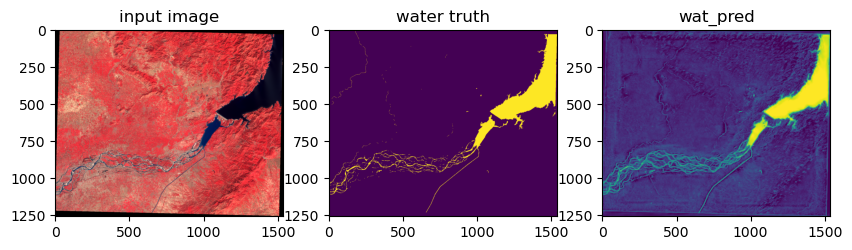

In [15]:
### show the results
wat_global_fea = wat_pred_logit.squeeze(0).detach().numpy()
# wat_global_fea = global_fea.squeeze(0).detach().numpy().transpose(1,2,0)
imsShow([scene_arr, truth_arr, wat_global_fea], 
        clip_list=[2, 2, 2], 
        color_bands_list = [[3,2,1], 0, [2,1,0]],
        img_name_list = ['input image', 'water truth', 'wat_pred'],
        figsize=(10, 3)); 


In [16]:
### processing for all validation scenes  
for path_scene in config.paths_val_scene:
    fea_save_dir = config.paths_val_scene[0].parent.with_name('scene_global_fea')
    scene_id = path_scene.stem
    print('scene id:', scene_id)
    with rio.open(path_scene) as scene_rio:
        scene_arr = scene_rio.read().transpose((1, 2, 0))  # (H,W,C)
        scene_tensor = torch.from_numpy(scene_arr.transpose(2,0,1)).unsqueeze(0)
        profile_fea = scene_rio.profile
        profile_fea.update(count=1, dtype="float32")
    ## Inference using trained model
    with torch.no_grad():
        wat_pred_logit, global_fea = model(scene_tensor)
        scene_fea = wat_pred_logit.squeeze(0).detach().numpy().transpose(1,2,0)
        # scene_fea = global_fea.squeeze(0).detach().numpy().transpose(1,2,0)
    path_save = str(fea_save_dir / (scene_id + '_fea.tif'))
    ## Save to path
    with rio.open(path_save, 'w', **profile_fea) as dst:
        for i in range(scene_fea.shape[2]):
            dst.write(scene_fea[:,:,i], i+1)   ## write to each band
    print('global_fea save to: ', path_save)
    # break



scene id: S2A_L2A_20190125_N0211_R034_S1
global_fea save to:  data/dset/val/scene_global_fea/S2A_L2A_20190125_N0211_R034_S1_fea.tif
scene id: S2A_L2A_20190206_N0211_R067_S3
global_fea save to:  data/dset/val/scene_global_fea/S2A_L2A_20190206_N0211_R067_S3_fea.tif
scene id: S2A_L2A_20190318_N0211_R061_S2
global_fea save to:  data/dset/val/scene_global_fea/S2A_L2A_20190318_N0211_R061_S2_fea.tif
scene id: S2A_L2A_20190429_N0211_R096_S1
global_fea save to:  data/dset/val/scene_global_fea/S2A_L2A_20190429_N0211_R096_S1_fea.tif
scene id: S2A_L2A_20190508_N0212_R078_S3
global_fea save to:  data/dset/val/scene_global_fea/S2A_L2A_20190508_N0212_R078_S3_fea.tif
scene id: S2A_L2A_20190716_N0213_R063_S2
global_fea save to:  data/dset/val/scene_global_fea/S2A_L2A_20190716_N0213_R063_S2_fea.tif
scene id: S2A_L2A_20190725_N0213_R054_S1
global_fea save to:  data/dset/val/scene_global_fea/S2A_L2A_20190725_N0213_R054_S1_fea.tif
scene id: S2A_L2A_20190811_N0213_R013_S2
global_fea save to:  data/dset/val/